In [1]:
import sklearn
import scipy
import numpy as np
import statsmodels.api as sms
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error
from sklearn.preprocessing import StandardScaler
from scipy.stats.mstats import winsorize
from sklearn.metrics import r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd
import seaborn as sns
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
print(f"Pandas Version: {pd.__version__}")
print(f"statsmodels Version: {sms.__version__}")
print(f"SkLearn Version: {sklearn.__version__}")
print(f"Seaborn Version: {sns.__version__}")
print(f"Scipy Version: {scipy.__version__}")
print(f"NumPy Version: {np.__version__}")

Pandas Version: 2.2.3
statsmodels Version: 0.15.0
SkLearn Version: 1.7.2
Seaborn Version: 0.13.2
Scipy Version: 1.16.2
NumPy Version: 2.2.0


# Data Preparation

In [2]:
#Import data
df = pd.read_csv("retail_ab_test_10000.csv")

In [3]:
df

,customer_id,week,experiment_group,region,device,traffic_source,loyalty_tier,age,income_k,prior_3mo_visits,prior_3mo_spend,session_duration_sec,pages_viewed,cart_adds,purchased,order_value,discount_applied,shipping_cost,returned,satisfaction_score
0,180325,12,Discount10,West,mobile,organic,Bronze,25,84.0,4,119.32,228,6,2,0,0.00,0.0,0.00,0,2
1,796559,28,Control,Northeast,tablet,organic,Silver,67,37.7,2,82.31,134,4,0,1,43.06,0.0,6.77,0,3
2,689113,35,Control,South,mobile,organic,Bronze,24,92.2,5,155.35,121,4,1,0,0.00,0.0,0.00,0,4
3,494990,14,Control,Midwest,mobile,affiliate,Silver,49,118.2,1,368.48,169,4,0,0,0.00,0.0,0.00,0,3
4,489713,40,Control,South,mobile,social,Bronze,52,99.5,6,128.10,362,7,2,0,0.00,0.0,0.00,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,997068,9,Discount10,South,tablet,paid_search,Bronze,38,50.7,7,39.20,114,8,4,0,0.00,0.0,0.00,0,5
9996,417868,20,FreeShip,Midwest,desktop,affiliate,Bronze,48,123.1,2,127.00,164,3,1,0,0.00,0.0,0.00,0,4
9997,608955,19,Discount10,West,mobile,paid_search,Bronze,27,57.9,6,180.26,75,4,2,0,0.00,0.0,0.00,0,4
9998,653706,26,Control,Northeast,desktop,email,Bronze,37,69.4,4,122.18,403,5,0,0,0.00,0.0,0.00,0,3


In [4]:
df.columns

Index(['customer_id', 'week', 'experiment_group', 'region', 'device',
       'traffic_source', 'loyalty_tier', 'age', 'income_k', 'prior_3mo_visits',
       'prior_3mo_spend', 'session_duration_sec', 'pages_viewed', 'cart_adds',
       'purchased', 'order_value', 'discount_applied', 'shipping_cost',
       'returned', 'satisfaction_score'],
      dtype='object')

In [5]:
#Removing rows that do not include a purchase
df = df.query('purchased != 0')

In [6]:
df.purchased.value_counts()

purchased
1    1348
Name: count, dtype: int64

In [7]:
#Dropping uneeded rows
df.drop(['customer_id','returned', 'device', 'purchased'], axis=1, inplace=True)

C:\Users\newfo\AppData\Local\Temp\ipykernel_34448\1599805987.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.drop(['customer_id','returned', 'device', 'purchased'], axis=1, inplace=True)


In [8]:
df.head()

,week,experiment_group,region,traffic_source,loyalty_tier,age,income_k,prior_3mo_visits,prior_3mo_spend,session_duration_sec,pages_viewed,cart_adds,order_value,discount_applied,shipping_cost,satisfaction_score
1,28,Control,Northeast,organic,Silver,67,37.7,2,82.31,134,4,0,43.06,0.0,6.77,3
23,5,Control,West,organic,Silver,31,122.6,5,148.28,253,4,0,44.65,0.0,5.50,4
32,27,Control,South,email,Silver,48,47.9,9,31.87,226,6,0,5.53,0.0,3.91,5
37,50,Discount10,Northeast,paid_search,Silver,45,59.8,9,30.62,497,7,2,8.95,0.1,2.86,3
40,48,Discount10,Northeast,organic,Gold,38,52.4,7,223.48,221,5,1,86.39,0.1,4.83,3


In [9]:
#Selects categorical independent features
df_xFeatsCat = df[['experiment_group', 'region',
       'traffic_source', 'loyalty_tier', 'discount_applied', 'satisfaction_score']]
df_xFeatsCat

,experiment_group,region,traffic_source,loyalty_tier,discount_applied,satisfaction_score
1,Control,Northeast,organic,Silver,0.0,3
23,Control,West,organic,Silver,0.0,4
32,Control,South,email,Silver,0.0,5
37,Discount10,Northeast,paid_search,Silver,0.1,3
40,Discount10,Northeast,organic,Gold,0.1,3
...,...,...,...,...,...,...
9968,Control,South,email,Silver,0.0,5
9972,FreeShip,West,social,Gold,0.0,4
9980,Discount10,South,organic,Silver,0.1,4
9982,Discount10,Midwest,email,Gold,0.1,4


In [10]:
df_xFeatsNum = df[['age', 'income_k',
                   'prior_3mo_visits', 'shipping_cost']]
df_xFeatsNum

,age,income_k,prior_3mo_visits,shipping_cost
1,67,37.7,2,6.77
23,31,122.6,5,5.50
32,48,47.9,9,3.91
37,45,59.8,9,2.86
40,38,52.4,7,4.83
...,...,...,...,...
9968,37,73.0,3,7.22
9972,30,67.9,7,0.00
9980,27,75.9,7,6.66
9982,34,53.4,3,6.55


In [11]:
df_yFeat = df[['order_value']]
df_yFeat

,order_value
1,43.06
23,44.65
32,5.53
37,8.95
40,86.39
...,...
9968,51.90
9972,66.43
9980,6.53
9982,30.39


In [12]:
#Finds descriptive analytics for numeric features
df_numericFeats = pd.concat([df_xFeatsNum, df_yFeat])
df_numericDescript = df_numericFeats.describe()
df_numericDescript.loc['variance'] = df_numericFeats.var()
df_numericDescript.loc['range'] = df_numericFeats.max() - df_numericFeats.min()
df_numericDescript

,age,income_k,prior_3mo_visits,shipping_cost,order_value
count,1348.000000,1348.000000,1348.000000,1348.000000,1348.000000
mean,37.221810,68.476261,5.980712,4.869770,45.400979
std,11.410238,24.699426,2.760886,3.295041,25.276979
min,18.000000,20.000000,0.000000,0.000000,0.000000
25%,29.000000,51.350000,4.000000,0.965000,26.200000
50%,37.000000,64.250000,6.000000,5.580000,44.450000
75%,45.000000,81.325000,8.000000,7.255000,62.692500
max,74.000000,192.100000,17.000000,12.660000,128.090000
variance,130.193525,610.061663,7.622493,10.857298,638.925642
range,56.000000,172.100000,17.000000,12.660000,128.090000


In [13]:
#Finds the descriptive analytics for the categorical features
for col in df_xFeatsCat.columns:
    print(f'{df_xFeatsCat[col].value_counts()}\n'
          f'{df_xFeatsCat[col].value_counts(normalize=True) * 100}')

experiment_group
Discount10    507
Control       505
FreeShip      336
Name: count, dtype: int64
experiment_group
Discount10    37.611276
Control       37.462908
FreeShip      24.925816
Name: proportion, dtype: float64
region
South        467
Northeast    300
West         297
Midwest      284
Name: count, dtype: int64
region
South        34.643917
Northeast    22.255193
West         22.032641
Midwest      21.068249
Name: proportion, dtype: float64
traffic_source
organic        465
paid_search    358
email          248
social         210
affiliate       67
Name: count, dtype: int64
traffic_source
organic        34.495549
paid_search    26.557864
email          18.397626
social         15.578635
affiliate       4.970326
Name: proportion, dtype: float64
loyalty_tier
Bronze      621
Silver      404
Gold        237
Platinum     86
Name: count, dtype: int64
loyalty_tier
Bronze      46.068249
Silver      29.970326
Gold        17.581602
Platinum     6.379822
Name: proportion, dtype: float64
di

In [14]:
def createNumPlots():
    df_NumFeats = pd.concat([df_xFeatsNum, df_yFeat], axis=1)
    lowCardFeats = ['prior_3mo_visits']
    for col in df_NumFeats.columns:
        plt.figure(figsize=(6, 4))
        df_NumFeats.boxplot(column=[col])
        plt.title(f"Boxplot of {col}")
        plt.ylabel("Value")
        plt.show()
        if col != 'order_value' and col not in lowCardFeats:
            df_NumFeats.plot.scatter(x=f'{col}', y='order_value', title=f'{col} vs order_value')
        #A violin plot is used for low cardinality features as it will show a more accurate representation of the data
        if col != 'order_value' and col in lowCardFeats:
            sns.violinplot(data=df_NumFeats, y='order_value', x=col)


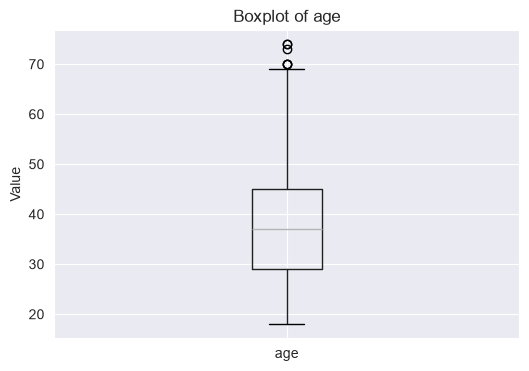

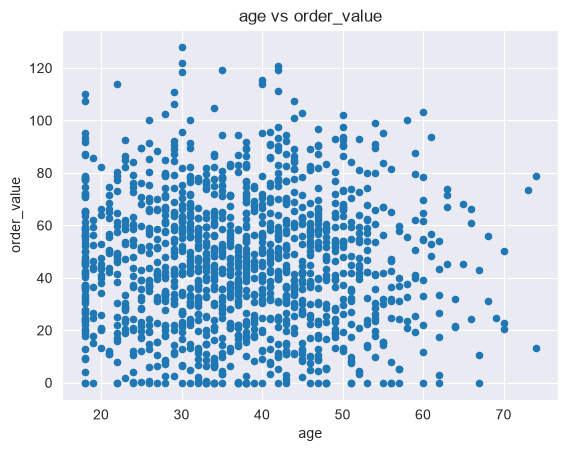

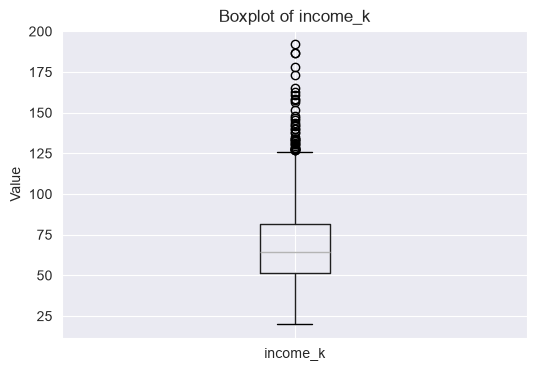

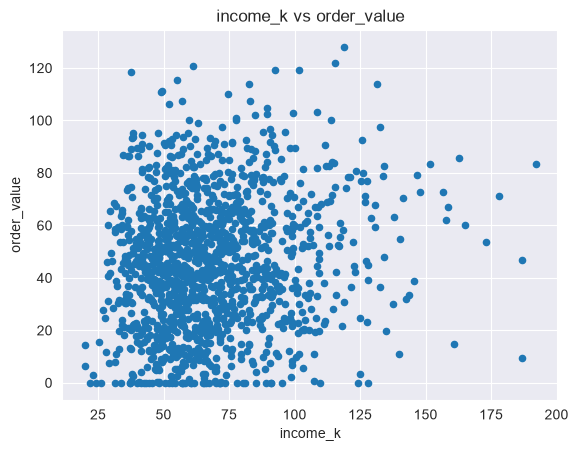

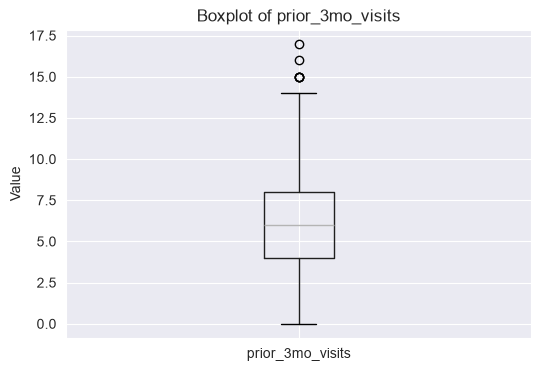

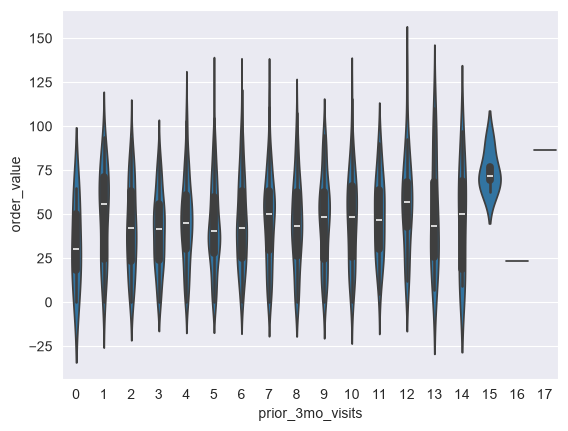

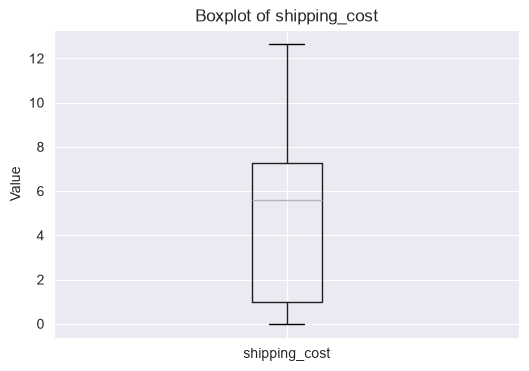

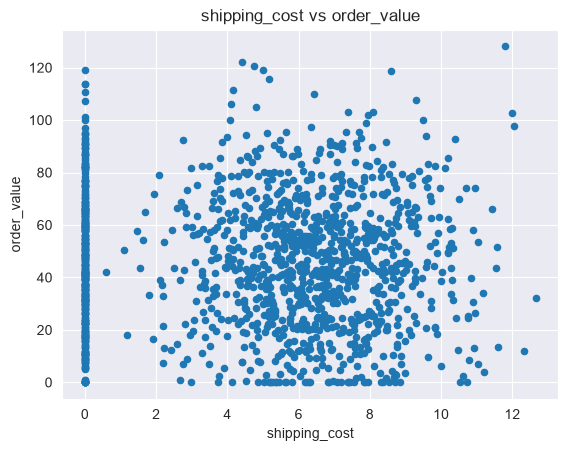

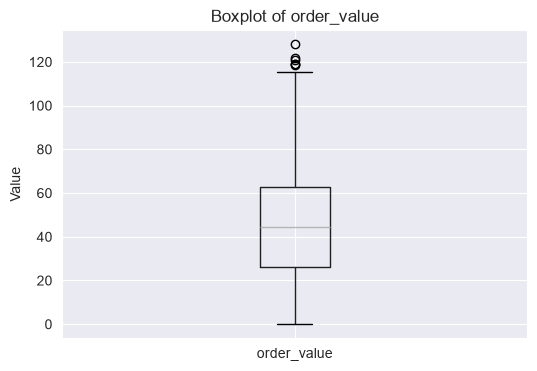

In [15]:
createNumPlots()

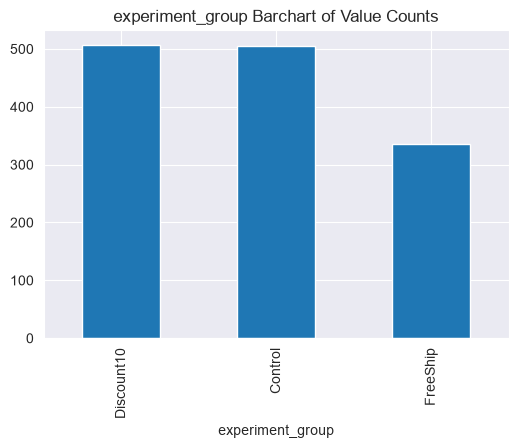

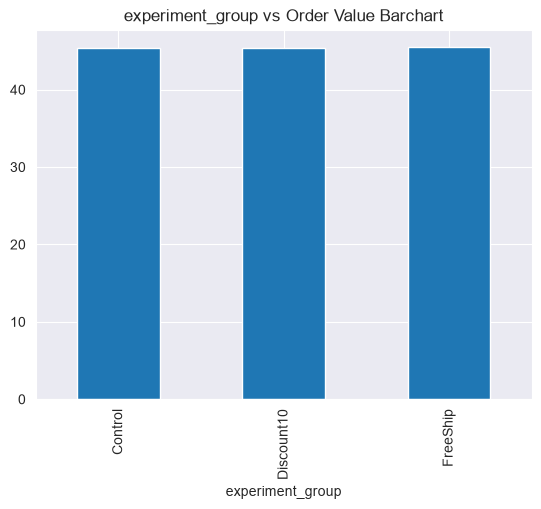

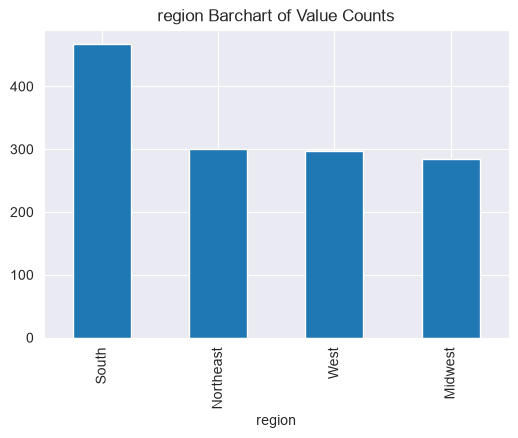

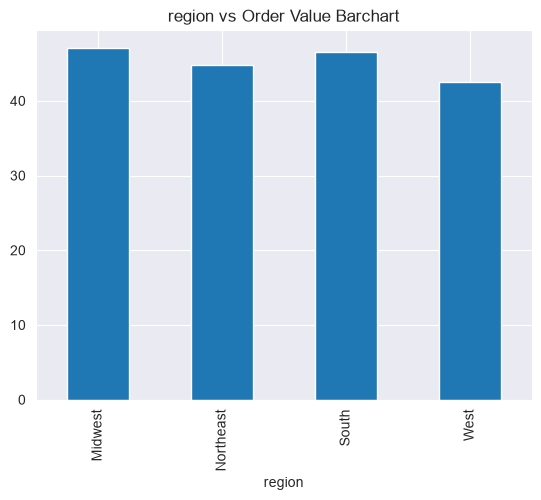

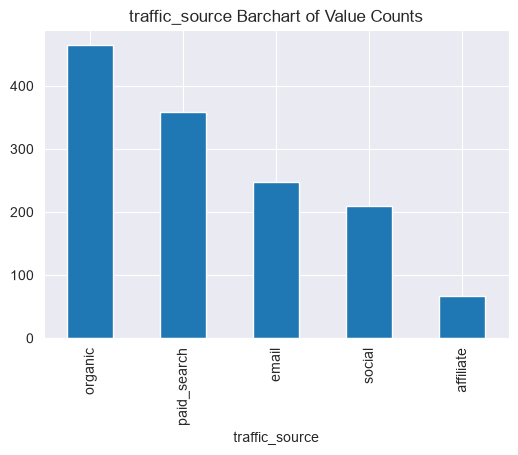

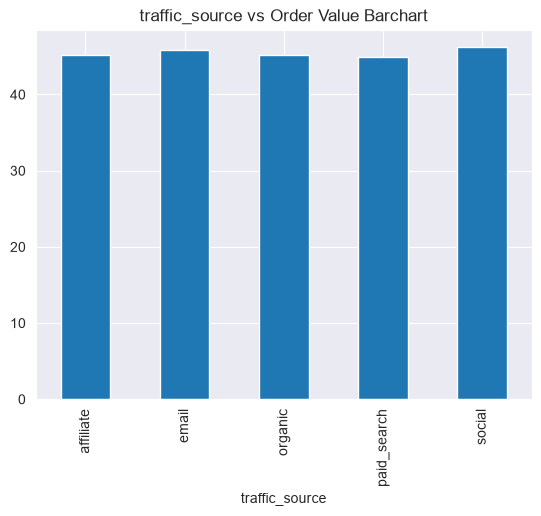

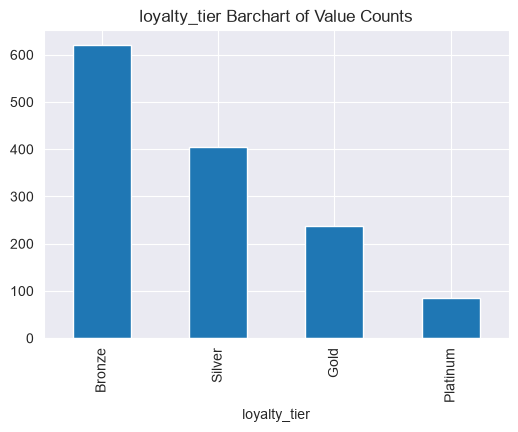

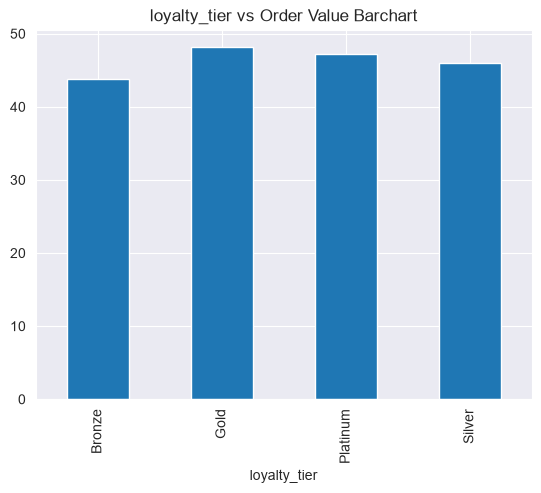

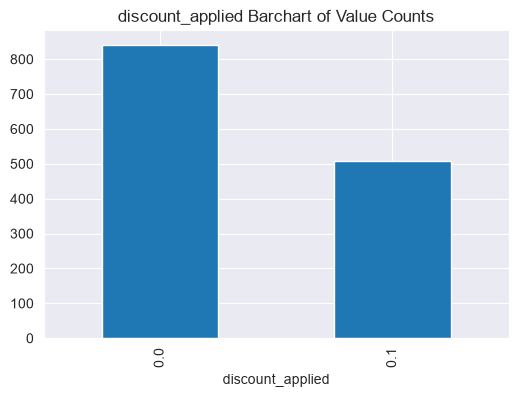

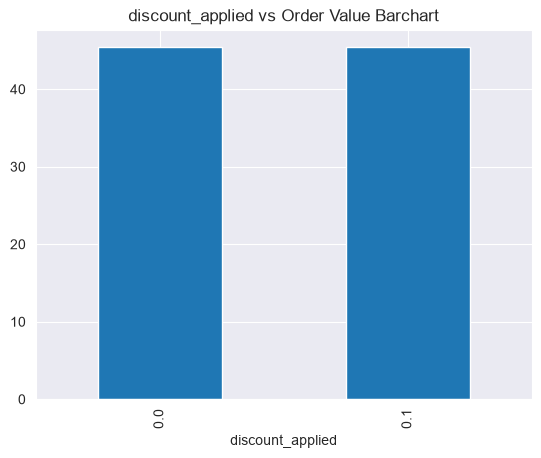

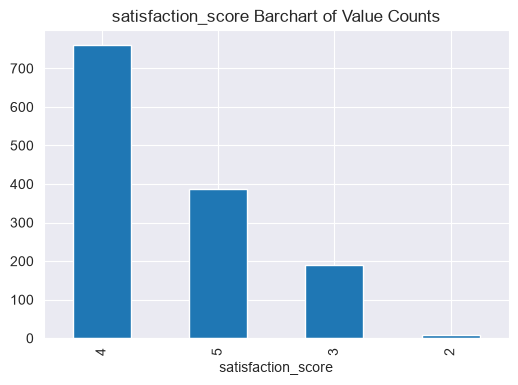

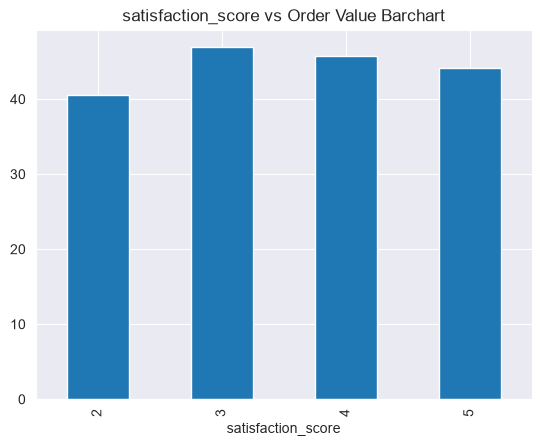

In [16]:
df_catPlot = pd.concat([df_xFeatsCat, df_yFeat], axis=1)
for col in df_xFeatsCat.columns:
    plt.figure(figsize=(6, 4))
    df_xFeatsCat[col].value_counts().plot(kind='bar', title=f'{col} Barchart of Value Counts')
    plt.show()
    df_catPlot.groupby(col)['order_value'].mean().plot(kind='bar', x=f'{col}', y='order_value', title=f'{col} vs Order Value Barchart')

In [17]:
for col in df_xFeatsNum.columns:
    df_xFeatsNum[col] = winsorize(df_xFeatsNum[col], limits=[0, 0.01])
df_xFeatsNum.income_k = winsorize(df_xFeatsNum.income_k, limits=[0, 0.033])
df_yFeat.order_value = winsorize(df_yFeat.order_value, limits=[0, 0.01])

C:\Users\newfo\AppData\Local\Temp\ipykernel_34448\1960163302.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_xFeatsNum[col] = winsorize(df_xFeatsNum[col], limits=[0, 0.01])
C:\Users\newfo\AppData\Local\Temp\ipykernel_34448\1960163302.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_xFeatsNum.income_k = winsorize(df_xFeatsNum.income_k, limits=[0, 0.033])
C:\Users\newfo\AppData\Local\Temp\ipykernel_34448\1960163302.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice fr

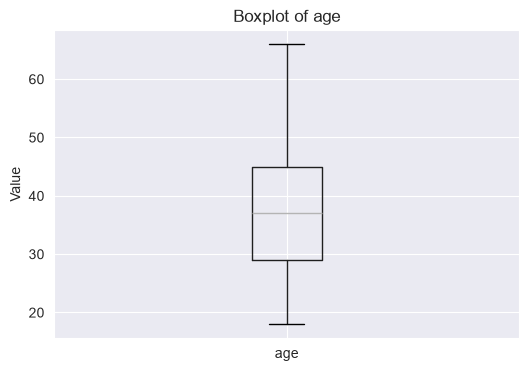

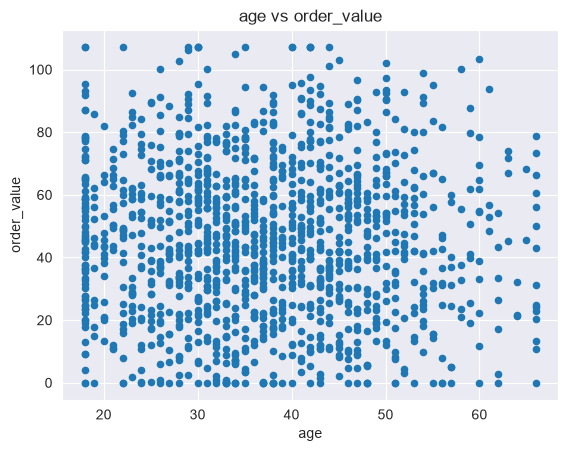

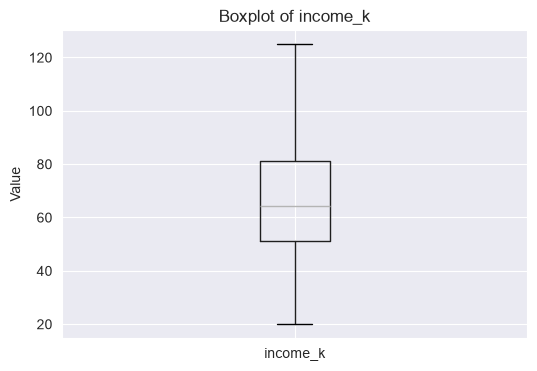

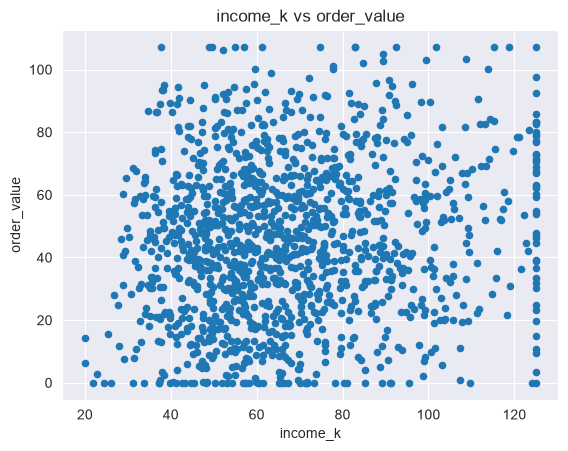

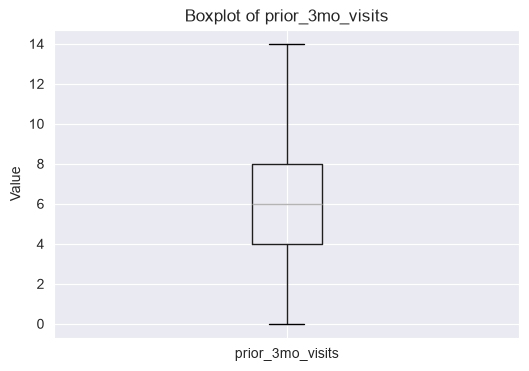

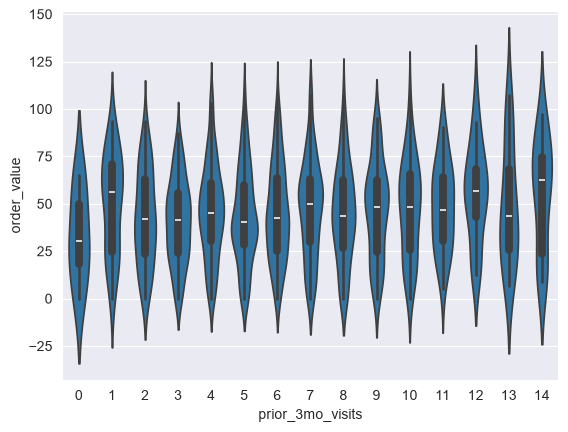

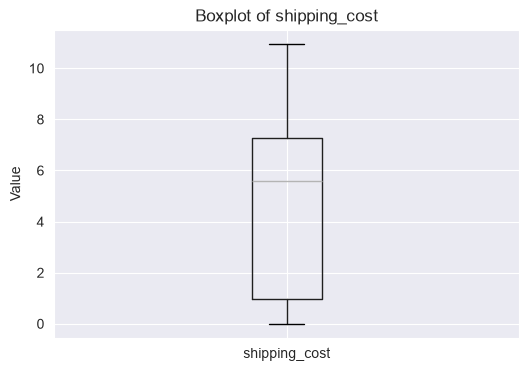

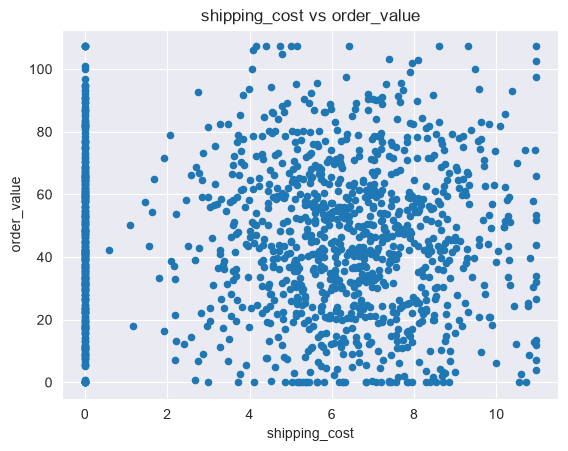

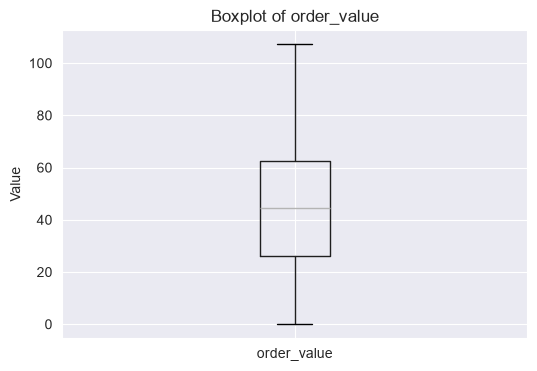

In [18]:
createNumPlots()

In [19]:
df_dummies = pd.get_dummies(df_xFeatsCat[['experiment_group','region','traffic_source','loyalty_tier']], drop_first=True, dtype=int)
df_dummies

,experiment_group_Discount10,experiment_group_FreeShip,region_Northeast,region_South,region_West,traffic_source_email,traffic_source_organic,traffic_source_paid_search,traffic_source_social,loyalty_tier_Gold,loyalty_tier_Platinum,loyalty_tier_Silver
1,0,0,1,0,0,0,1,0,0,0,0,1
23,0,0,0,0,1,0,1,0,0,0,0,1
32,0,0,0,1,0,1,0,0,0,0,0,1
37,1,0,1,0,0,0,0,1,0,0,0,1
40,1,0,1,0,0,0,1,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
9968,0,0,0,1,0,1,0,0,0,0,0,1
9972,0,1,0,0,1,0,0,0,1,1,0,0
9980,1,0,0,1,0,0,1,0,0,0,0,1
9982,1,0,0,0,0,1,0,0,0,1,0,0


In [20]:
df_xFeatsCat.discount_applied.replace({0.1: 1, 0.0: 0}, inplace=True)
df_xFeatsCat.discount_applied = df_xFeatsCat.discount_applied.astype(int)

C:\Users\newfo\AppData\Local\Temp\ipykernel_34448\1365631849.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_xFeatsCat.discount_applied.replace({0.1: 1, 0.0: 0}, inplace=True)
C:\Users\newfo\AppData\Local\Temp\ipykernel_34448\1365631849.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_xFeatsCat.discount_applied.replace({0.1: 1, 0.

In [21]:
df_xFeatsCat = pd.concat([df_xFeatsCat[['discount_applied', 'satisfaction_score']], df_dummies], axis=1)

In [22]:
df_xFeatsCat

,discount_applied,satisfaction_score,experiment_group_Discount10,experiment_group_FreeShip,region_Northeast,region_South,region_West,traffic_source_email,traffic_source_organic,traffic_source_paid_search,traffic_source_social,loyalty_tier_Gold,loyalty_tier_Platinum,loyalty_tier_Silver
1,0,3,0,0,1,0,0,0,1,0,0,0,0,1
23,0,4,0,0,0,0,1,0,1,0,0,0,0,1
32,0,5,0,0,0,1,0,1,0,0,0,0,0,1
37,1,3,1,0,1,0,0,0,0,1,0,0,0,1
40,1,3,1,0,1,0,0,0,1,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9968,0,5,0,0,0,1,0,1,0,0,0,0,0,1
9972,0,4,0,1,0,0,1,0,0,0,1,1,0,0
9980,1,4,1,0,0,1,0,0,1,0,0,0,0,1
9982,1,4,1,0,0,0,0,1,0,0,0,1,0,0


In [23]:
df_xFeats = pd.concat([df_xFeatsCat, df_xFeatsNum], axis=1)

The baseline values for the features that needed dummies are: experiment_group: control, region: midwest, traffic_source: affiliate, loyalty_tier: Bronze

# Regression

In [24]:
#Splits data into test and training sets
X_train, X_test, y_train, y_test = train_test_split(
    df_xFeats, df_yFeat, test_size=0.2, random_state=42
)
X_train.to_csv('X_train.csv')
X_test.to_csv('X_test.csv')
y_train.to_csv('y_train.csv')
y_test.to_csv('y_test.csv')

In [25]:
#Creates a scaler for the data
scaler = StandardScaler().set_output(transform="pandas")
# Fit to training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

In [26]:
#Saves the scaled training data (pre-optimization) to a .csv file
X_train_scaled.to_csv('ScaledTrainingData.csv')

In [27]:
#Reads the saved scaled training data
X_train_scaled = pd.read_csv('ScaledTrainingData.csv', index_col=0)

In [28]:
model = sms.OLS(y_train, sms.add_constant(X_train_scaled)).fit()
model.summary()

C:\Users\newfo\AppData\Local\Temp\ipykernel_34448\3899309545.py:1: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = sms.OLS(y_train, sms.add_constant(X_train_scaled)).fit()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            order_value   R-squared:                       0.040
Model:                            OLS   Adj. R-squared:                  0.025
Method:                 Least Squares   F-statistic:                     2.592
Date:                Wed, 30 Sep 2026   Prob (F-statistic):           0.000410
Time:                        18:37:17   Log-Likelihood:                -4977.2
No. Observations:                1078   AIC:                             9990.
Df Residuals:                    1060   BIC:                         1.008e+04
Df Model:                          17                                         
Covariance Type:            nonrobust                                         
===============================================================================================
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
const                          45.5628      0.752     60.580      0.000      44.087      47.039
discount_applied                0.1295      0.423      0.306      0.759      -0.700       0.959
satisfaction_score             -0.4929      0.759     -0.649      0.516      -1.982       0.996
experiment_group_Discount10     0.1295      0.423      0.306      0.759      -0.700       0.959
experiment_group_FreeShip       1.2292      1.505      0.817      0.414      -1.724       4.182
region_Northeast               -0.6791      0.956     -0.711      0.478      -2.554       1.196
region_South                    0.2329      1.001      0.233      0.816      -1.732       2.198
region_West                    -1.9219      0.962     -1.999      0.046      -3.809      -0.035
traffic_source_email           -0.9555      1.487     -0.643      0.521      -3.873       1.962
traffic_source_organic         -1.4164      1.710     -0.828      0.408      -4.772       1.939
traffic_source_paid_search     -1.7288      1.641     -1.054      0.292      -4.949       1.491
traffic_source_social          -0.6343      1.410     -0.450      0.653      -3.401       2.133
loyalty_tier_Gold               1.0822      0.865      1.251      0.211      -0.615       2.780
loyalty_tier_Platinum           0.1961      0.863      0.227      0.820      -1.498       1.890
loyalty_tier_Silver             0.4458      0.822      0.543      0.588      -1.167       2.058
age                            -0.6278      0.757     -0.829      0.407      -2.114       0.858
income_k                        4.0225      0.759      5.302      0.000       2.534       5.511
prior_3mo_visits                1.7312      0.871      1.988      0.047       0.022       3.440
shipping_cost                   0.6242      1.456      0.429      0.668      -2.232       3.481
==============================================================================
Omnibus:                       26.752   Durbin-Watson:                   2.033
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               17.055
Skew:                           0.167   Prob(JB):                     0.000198
Kurtosis:                       2.483   Cond. No.                     1.81e+15
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The smallest eigenvalue is 9.18e-28. This might indicate that there are
strong multicollinearity problems or that the design matrix is singular.
"""

In [29]:
#Based on: https://ujangriswanto08.medium.com/how-to-perform-stepwise-regression-in-python-using-statsmodels-2d2cda4e900a
#Author: Ujang Riswanto
#Title: How to Perform Stepwise Regression in Python Using statsmodels
#Date Accessed: 9/2/26

def forward_selection(X, y):
    selected_features = []
    remaining_features = list(X.columns)
    best_aic = float('inf')

    while remaining_features:
        aic_with_candidates = []

        for candidate in remaining_features:
            model = sms.OLS(y, sms.add_constant(X[selected_features + [candidate]])).fit()
            aic_with_candidates.append((model.aic, candidate))

        aic_with_candidates.sort()  # Sort by AIC
        best_new_aic, best_candidate = aic_with_candidates[0]

        if best_new_aic < best_aic:
            best_aic = best_new_aic
            selected_features.append(best_candidate)
            remaining_features.remove(best_candidate)
        else:
            break

    return selected_features

# Call the function
best_features = forward_selection(X_train, y_train)
print("Selected features:", best_features)

Selected features: ['income_k', 'prior_3mo_visits', 'region_West']


In [30]:
best_features.insert(-1, 'region_South')
best_features.insert(-1, 'region_Northeast')

As forward step-wise elimination kept a dummy feature from the region feature, that means either all dummy features need to be included or none. I will keep all of them as it keeps the theme of forward stepwise elimination adding features.

In [31]:
#Keeps features that survived backward step elimination
X_train_optimized = X_train_scaled[best_features]

In [32]:
X_train_optimized.to_csv('OptimizedTrainingData.csv')

In [33]:
X_train_final = pd.read_csv('OptimizedTrainingData.csv', index_col=0)

In [34]:
#Runs model after optimizations
model = sms.OLS(y_train, sms.add_constant(X_train_final )).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            order_value   R-squared:                       0.035
Model:                            OLS   Adj. R-squared:                  0.031
Method:                 Least Squares   F-statistic:                     7.798
Date:                Wed, 30 Sep 2026   Prob (F-statistic):           3.21e-07
Time:                        18:37:17   Log-Likelihood:                -4979.9
No. Observations:                1078   AIC:                             9972.
Df Residuals:                    1072   BIC:                         1.000e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const               45.5628      0.750     60.770      0.000      44.092      47.034
income_k             3.9451      0.751      5.252      0.000       2.471       5.419
prior_3mo_visits     2.0088      0.751      2.675      0.008       0.535       3.483
region_South         0.2480      0.994      0.250      0.803      -1.702       2.198
region_Northeast    -0.6385      0.951     -0.671      0.502      -2.504       1.227
region_West         -1.8659      0.956     -1.952      0.051      -3.741       0.009
==============================================================================
Omnibus:                       27.973   Durbin-Watson:                   2.037
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               17.389
Skew:                           0.164   Prob(JB):                     0.000168
Kurtosis:                       2.471   Cond. No.                         2.25
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [35]:
#Scales test set with scaler
X_test_scaled = scaler.transform(X_test)

In [36]:
#Selects features that survived stepwise elimination
X_test_scaled = X_test_scaled[best_features]

In [37]:
X_test_scaled.to_csv('FinalTestData.csv')

In [38]:
X_final = pd.read_csv('FinalTestData.csv', index_col=0)

In [39]:
#Predicts y-values
y_pred = model.predict(sms.add_constant(X_final))

# Regression Results

In [40]:
#Retrieve training set residuals from model
train_residuals = model.resid
train_residuals

5543    -4.689737
843     28.841796
3074   -31.035235
6869     4.691356
2912    44.489251
          ...    
8248    32.661566
8495   -54.492328
9675   -20.373458
6268    -1.823431
8456   -13.454290
Length: 1078, dtype: float64

In [41]:
results = pd.DataFrame({'Actual': y_test.order_value.tolist(), 'Predicted': y_pred})

In [42]:
results['Residuals'] = results.Actual - results.Predicted
results.Residuals = pd.to_numeric(results.Residuals)

In [43]:
#Calculates Train RMSE
train_rmse = np.sqrt(model.mse_resid)
print(f"Train Set Root Mean Square Error: {train_rmse:.4f}")

Train Set Root Mean Square Error: 24.6166


In [44]:
#Calculates Test RMSE
test_rmse = root_mean_squared_error(y_test, y_pred)
print(f"Test Set Root Mean Square Error: {test_rmse:.4f}")

Test Set Root Mean Square Error: 24.9194


In [45]:
print(f"Difference in RMSE: {test_rmse - train_rmse:.4f}")

Difference in RMSE: 0.3027


In [46]:
#Calculates Train MAE
train_mae = np.mean(np.abs(train_residuals))
print(f"Train Set Mean Absolute Error: {train_mae:.4f}")

Train Set Mean Absolute Error: 20.1197


In [47]:
#Calculates Test MAE
test_mae = np.mean(np.abs(results.Residuals))
print(f"Test Set Mean Absolute Error: {test_mae:.4f}")

Test Set Mean Absolute Error: 20.2808


In [48]:
print(f"Difference in MAE: {test_mae - train_mae:.4f}")

Difference in MAE: 0.1611


In [49]:
r2_train_score = model.rsquared
adj_r2_train_score = model.rsquared_adj
print(f"Train R2 Score: {r2_train_score:.4f}")
print(f"Train Adjusted R2 Score: {adj_r2_train_score:.4f}")

Train R2 Score: 0.0351
Train Adjusted R2 Score: 0.0306


In [50]:
#Calculates r2 and adjusted r2 of the test model
r2_test_score = r2_score(y_test, y_pred)
print(f"Test R2 Score: {r2_test_score:.4f}")
n = X_test_scaled.shape[0]
p =  X_test_scaled.shape[1]
adj_r2_score = 1 - (1 - r2_test_score) * (n - 1) / (n - p - 1)
print(f"Test Adjusted R2 Score: {adj_r2_score:.4f}")

Test R2 Score: 0.0209
Test Adjusted R2 Score: 0.0023


statsmodels.api: Used for OLS, my choice multiple linear regression algorithm as its summary function of the model is great for displaying various information.  \
  \
variance_inflation_factor from statsmodels.stats.outliers_influence: Used to find multicollinearity during optimization.  \
  \
train_test_split from sklearn.model_selection: I used this for splitting my data into training and test sets as it is my preferred way of splitting my dataset.  \
  \
root_mean_squared_error from sklearn.metrics: I used this for calculating the root mean squared error without calculating it manually with numpy.  \
  \
r2_score from sklearn.metrics: I used this for calculating the r2 score of the model on the test dataset.  \
  \
StandardScaler from sklearn.preprocessing: I used this for scaling my dependent features as my features needed to be scaled due to the difference in values between features.  \
  \
winsorize from scipy.stats.mstats: I used winsorization during data cleaning to reduce the affect of outliers in the data without completely removing the data, winsorization reduces/increases data to the quartile given, for example: you can increase data below the 1st quartile to be at minimum the 1st quartile so that the extremity of the value does not affect analysis and the value/row is not removed from the dataset.  \
  \
pandas: pandas was used as my main data manipulation/analysis tool by converting the data into a dataframe and manipulating it through various functions/methods, it also allowed me to generate most visualizations.  \
  \
seaborn: Simply used to create one of my visualizations (a strip plot) as it was my preferred way of visualization data for one of the visualizations, it was also used during the last section to confirm Linear Regression assumptions.  \
  \
numpy: Used to calculate the train set RMSE (Root Mean Square Error).

In [51]:
X_test_scaled.head()

,income_k,prior_3mo_visits,region_South,region_Northeast,region_West
2322,-0.454375,0.392905,-0.737843,1.904366,-0.539461
5934,0.706117,-1.058858,1.355301,-0.525109,-0.539461
5912,2.544301,-0.695917,-0.737843,-0.525109,-0.539461
5978,0.387203,1.118787,-0.737843,-0.525109,1.853703
8131,-0.418940,0.755846,-0.737843,-0.525109,-0.539461


In [52]:
intercept = model.params['const']
coef_x1 = model.params['income_k']
coef_x2 = model.params['prior_3mo_visits']
coef_x3 = model.params['region_South']
coef_x4 = model.params['region_Northeast']
coef_x5 = model.params['region_West']


In [53]:
equation = f"Order Value = {intercept:.2f} + {coef_x1:.2f}('z-score income_k') + {coef_x2:.2f}('z-score prior_3mo_visits') + {coef_x3:.2f}('z-score region_South') + {coef_x4:.2f}('z-score region_Northeast')+ {coef_x5:.2f}('z-score region_West')"
equation

"Order Value = 45.56 + 3.95('z-score income_k') + 2.01('z-score prior_3mo_visits') + 0.25('z-score region_South') + -0.64('z-score region_Northeast')+ -1.87('z-score region_West')"

# Multiple Linear Regression Assumption Tests and Checks

Linear Relationship Test

<Axes: title={'center': 'income_k vs order_value'}, xlabel='income_k', ylabel='order_value'>

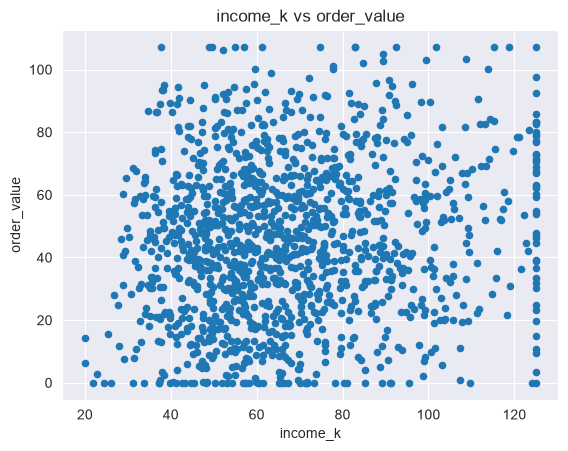

In [54]:
df_plotfeats = pd.concat([df_xFeats[['income_k','prior_3mo_visits','region_South', 'region_Northeast','region_West']], df_yFeat], axis=1)
df_plotfeats.plot.scatter(x='income_k', y='order_value', title=f'income_k vs order_value')

<Axes: xlabel='prior_3mo_visits', ylabel='order_value'>

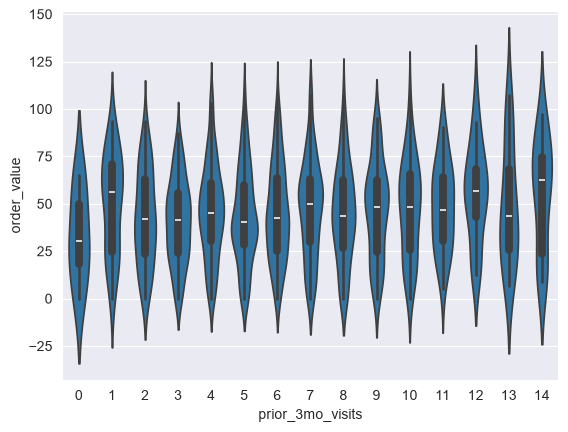

In [55]:
sns.violinplot(data=df_plotfeats, y='order_value', x='prior_3mo_visits')

<Axes: title={'center': 'region_South vs Average Order Value Barchart'}, xlabel='region_South'>

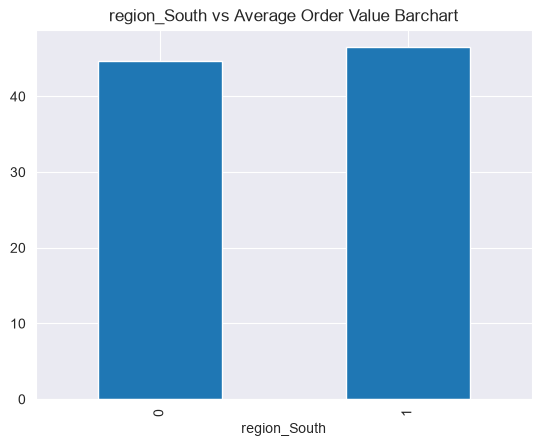

In [56]:
df_plotfeats.groupby('region_South')['order_value'].mean().plot(kind='bar', x=f'region_South', y='order_value', title=f'region_South vs Average Order Value Barchart')

<Axes: title={'center': 'region_Northeast vs Average Order Value Barchart'}, xlabel='region_Northeast'>

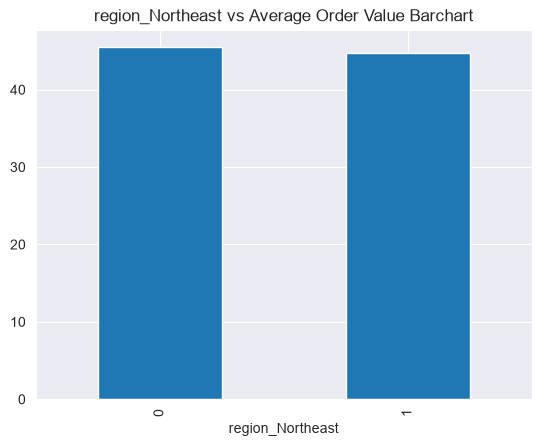

In [57]:
df_plotfeats.groupby('region_Northeast')['order_value'].mean().plot(kind='bar', x=f'region_Northeast', y='order_value', title=f'region_Northeast vs Average Order Value Barchart')

<Axes: title={'center': 'region_West vs Average Order Value Barchart'}, xlabel='region_West'>

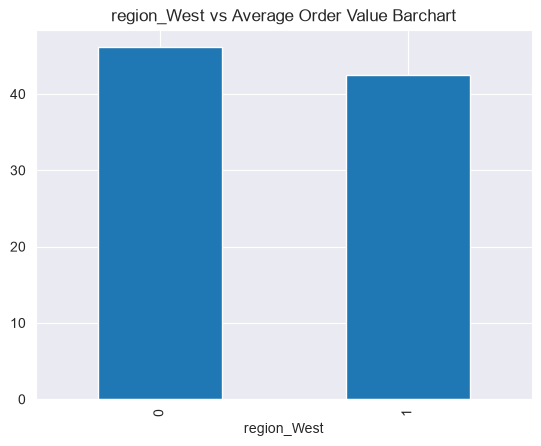

In [58]:
df_plotfeats.groupby('region_West')['order_value'].mean().plot(kind='bar', x=f'region_West', y='order_value', title=f'region_West vs Average Order Value Barchart')

We can see that there is a rough positive linear relationship for both income_k and prior_3mo_visits as order_value seems to somewhat trend upwards in both variables. For the categorical features, we can see that there is a significant difference between average order value for region_West, with a less significant, but present, difference between average order values for region_Northeast and region_South, which is expected as the stepwise elimination did not choose to keep these two features; however, for region_West to be present, these must be as well.

Test 2: No Multicollinearity

In [59]:
#Based on: https://www.statology.org/how-to-calculate-vif-in-python/
#Author: Zach Bobbit
#Title: How to Calculate VIF in Python
#Date Accessed: 9/27/2026

#Checks for multicollinearity in surviving features using variance inflation factor
vif = pd.DataFrame()
vif['VIF'] = [variance_inflation_factor(X_train_optimized.values, i) for i in range(X_train_optimized.shape[1])]
vif['variable'] = X_train_optimized.columns
vif

,VIF,variable
0,1.003602,income_k
1,1.003473,prior_3mo_visits
2,1.757323,region_South
3,1.608684,region_Northeast
4,1.624815,region_West


As all features have a VIF value close to 1 (the lowest possible value) that means that there is low to no multicollinearity between the surviving features

Test 3: Independence using a Durbin-Watson Test

In [60]:
#Performs Durbin-Watson test
durbin_watson(model.resid)

np.float64(2.0368324985133794)

As the value is between 1.5 and 2.5; and the value is very close to 2, there is very little to no autocorrelation in the model, meaning the variables are independent.

    Test 4: Homoscedasticity

In [61]:
bp_test = het_breuschpagan(model.resid, model.model.exog)
labels = ['Lagrange Multiplier statistic', 'p-value', 'f-value', 'f p-value']
print("Breusch-Pagan Test Results:")
for label, value in zip(labels, bp_test):
    print(f"{label}: {value:.4f}")
print(f"From the results of the Breusch-Pagan Test, we can: ")
p_val = bp_test[1]
if p_val >= 0.05:
    print(
        "Fail to reject the null hypothesis: There is no statistical evidence of heteroscedasticity, the data is homoscedastic")
else:
    print("Reject the null hypothesis: There is significant evidence the data is heteroscedastic")

Breusch-Pagan Test Results:
Lagrange Multiplier statistic: 4.6938
p-value: 0.4544
f-value: 0.9376
f p-value: 0.4556
From the results of the Breusch-Pagan Test, we can: 
Fail to reject the null hypothesis: There is no statistical evidence of heteroscedasticity, the data is homoscedastic


As seen from the test, there is no statistical evidence of heteroscedasticity, therefore the data is homoscedastic

Test 5: Multivariate Normality Test

Text(0.5, 0, 'Training Residuals')

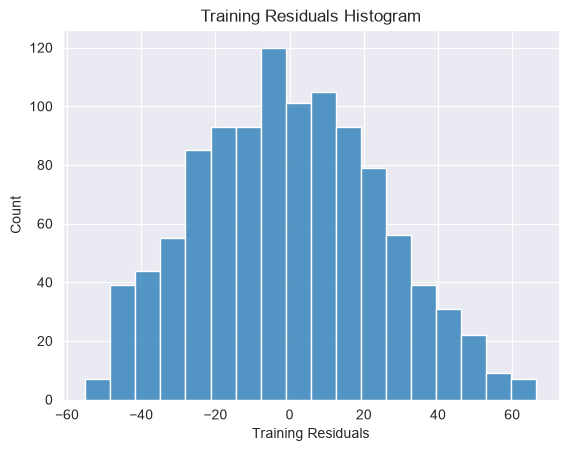

In [62]:
train_ax = sns.histplot(train_residuals)
train_ax.set_title("Training Residuals Histogram")
train_ax.set_xlabel("Training Residuals")

Text(0.5, 0, 'Testing Residuals')

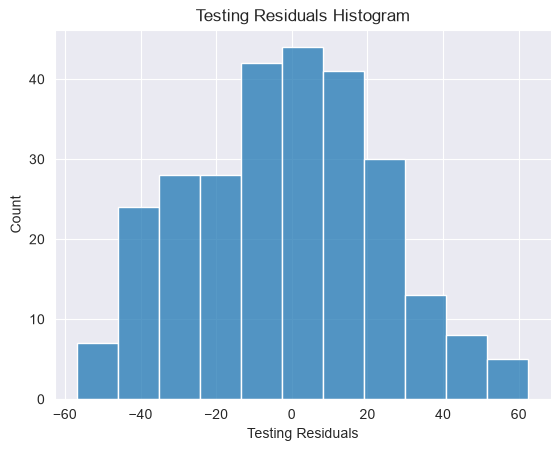

In [63]:
test_ax = sns.histplot(results.Residuals)
test_ax.set_title("Testing Residuals Histogram")
test_ax.set_xlabel("Testing Residuals")

From the histograms of both test and training residuals, we can see that there is a slight right skew-ness, which means our model is more likely to overpredict order value, if it were a reliable model (residuals are calculated by subtracting the actual y value from the predicted y values), and there are more outliers on the right side of the histograms as well.

Text(0.5, 0.98, 'Q-Q Plot of Training Set Residuals')

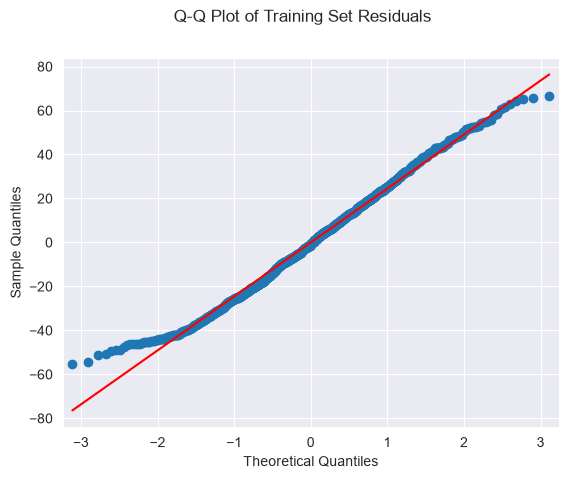

In [64]:
train_fig = sms.qqplot(train_residuals, line='s')
train_fig.suptitle("Q-Q Plot of Training Set Residuals")

Text(0.5, 0.98, 'Q-Q Plot of Test Set Residuals')

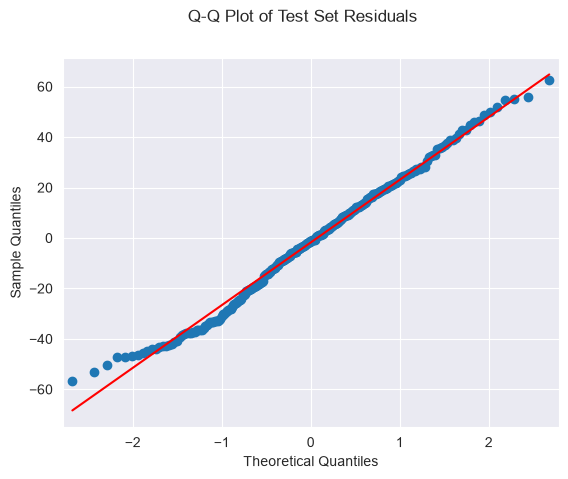

In [65]:
test_fig = sms.qqplot(results.Residuals, line='s')
test_fig.suptitle("Q-Q Plot of Test Set Residuals")

From these Q-Q plots we can see a similar result as our histograms. We can see that towards the left side of the plot, the values start to deviate more from the red line. The values also deviate at the very left of the plot, in normal distributions this can be normal. However, the residuals do not deviate enough to consider the values non-normalized.

From these two sets of visualizations, we can say that the distributions are normal (slightly skewed but normal enough) to satisfy the multivariate normality assumption of linear regression.